In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import plotly.express as px

In [7]:
df=pd.read_csv("social_media_engagement_5000.csv")

In [9]:
df.dtypes   

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [11]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [12]:
df['posted_at'] = pd.to_datetime(df['posted_at'], format='%d-%m-%Y')
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [13]:
for col in ['age','likes','comments','shares']:
  df[col]=df[col].astype('Int64')
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,text,travel,13487,<NA>,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [14]:
for col in ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment']:
    df[col] = df[col].astype('category')
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,text,travel,13487,<NA>,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [15]:
df['hashtags_list'] = df['hashtags'].str.split()

In [16]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
hashtags_list         0
dtype: int64

In [17]:
for col in ['age', 'likes', 'comments', 'shares']:
    if df[col].isnull().any():
        median_val = df[col].median()

        if pd.api.types.is_integer_dtype(df[col]):
            df[col] = df[col].fillna(int(median_val))
        else:
            df[col] = df[col].fillna(median_val)

for col in ['gender', 'sentiment']:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
     

In [18]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
hashtags_list       0
dtype: int64

In [19]:
gender_map = {
    'M': 'Male', 'Male': 'Male',
    'F': 'Female', 'Female': 'Female',
    'Other': 'Other'
}
df['gender'] = df['gender'].map(gender_map)

for col in ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment']:
    df[col] = df[col].astype('category')
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtags_list
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,"[#foodie, #travel, #love]"
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,[#fitness]
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,[#foodie]
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,"[#music, #foodie, #fun]"
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,[#travel]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,"[#travel, #fun]"
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,"[#foodie, #reels]"
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,"[#lifestyle, #tech]"
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,"[#reels, #love, #fitness]"


In [20]:
for col in ['likes', 'comments', 'shares']:
    df.loc[df[col] < 0, col] = pd.NA

mask = df['likes'] > df['impression_count']
df.loc[mask, 'likes'] = df.loc[mask, 'impression_count']

for col in ['likes', 'comments', 'shares']:
    df[col] = df[col].fillna(df[col].median()).round().astype('Int64')

In [21]:
if 'hashtags_list' in df.columns:
    df = df.drop(columns=['hashtags_list'])


duplicate_rows_before = df.duplicated().sum()
print(f"Number of duplicate rows before removal: {duplicate_rows_before}")


df.drop_duplicates(inplace=True)


duplicate_rows_after = df.duplicated().sum()
print(f"Number of duplicate rows after removal: {duplicate_rows_after}")
print(f"New DataFrame shape: {df.shape}")

Number of duplicate rows before removal: 0
Number of duplicate rows after removal: 0
New DataFrame shape: (5000, 19)


In [22]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,image,fitness,6019,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [23]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54,Other,Japan,712252,text,travel,14234,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [24]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [25]:
df.shape

(5000, 19)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   Int64         
 2   gender            5000 non-null   category      
 3   country           5000 non-null   category      
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   category      
 6   post_category     5000 non-null   category      
 7   likes             5000 non-null   Int64         
 8   comments          5000 non-null   Int64         
 9   shares            5000 non-null   Int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [27]:
df.dtypes

user_id                      int64
age                          Int64
gender                    category
country                   category
post_id                      int64
post_type                 category
post_category             category
likes                        Int64
comments                     Int64
shares                       Int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type               category
sentiment                 category
hashtags                       str
engagement_rate            float64
dtype: object

In [28]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.0,5000.000000,5000.0,5000.0,5000.0,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.4404,548042.909000,9457.719,1502.0398,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.0,100068.000000,10.0,0.0,0.0,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.0,322543.500000,4561.25,792.0,511.0,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.0,548077.500000,9382.0,1497.0,1012.0,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.0,771574.500000,14155.75,2235.25,1483.0,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.0,999455.000000,19998.0,2999.0,1999.0,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5667.384439,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [30]:
df.value_counts()

user_id  age  gender  country  post_id  post_type  post_category  likes  comments  shares  watch_time_sec  impression_count  posted_at   follower_count  is_verified  device_type  sentiment  hashtags                     engagement_rate
25795    43   Female  Brazil   496713   image      fitness        7011   354       1157    5726            44650             2022-12-17  81734           False        mobile       negative   #foodie #travel #love        0.190862           1
10860    33   Male    Brazil   157326   reel       food           11750  2606      1807    5947            80216             2023-06-02  5963            False        mobile       negative   #fitness                     0.201493           1
86820    32   Female  UK       109864   text       food           4862   344       955     6946            44858             2023-05-07  501783          False        tablet       positive   #foodie                      0.137345           1
64886    51   Other   France   848877   text 

In [31]:
categorical_cols = ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment']

for col in categorical_cols:
    print(f"--- {col} ---")
    print(f"unique: {df[col].nunique()}")
    print(df[col].value_counts())
    print()

--- gender ---
unique: 3
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

--- country ---
unique: 10
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
Australia    493
UK           493
Germany      490
Japan        472
Name: count, dtype: int64

--- post_type ---
unique: 4
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

--- post_category ---
unique: 8
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

--- device_type ---
unique: 3
device_type
mobile     1684
desktop    1658
tablet     1658
Name: count, dtype: int64

--- sentiment ---
unique: 3
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64



In [32]:
corr_matrix = df.select_dtypes(include='number').corr()
print(corr_matrix)
     

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.027645 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.031627 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.010723 -0.010540  0.001846   
likes             0.027645 -0.031627  0.010723  1.000000 -0.013195 -0.001150   
comments         -0.033395 -0.007284 -0.010540 -0.013195  1.000000  0.006142   
shares            0.013763  0.013871  0.001846 -0.001150  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.002956 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.187378 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.027476 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008039  0.010139 -0.146343  0.000051  0.021724   

                  watch_time_sec  impression_count  follower_count  \
user_id                -0.016847          0.01532

In [33]:
df.groupby('post_type')['likes'].mean()

post_type
image    9447.657578
reel     9513.701481
text     9415.845783
video    9451.884898
Name: likes, dtype: Float64

In [34]:
df.groupby('country')['impression_count'].mean()

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64

In [35]:
df.groupby('post_type')['likes'].agg(['mean', 'median', 'sum', 'count'])

,mean,median,sum,count
post_type,,,,
image,9447.657578,9424.0,11781229,1247
reel,9513.701481,9498.0,12206079,1283
text,9415.845783,9106.0,11722728,1245
video,9451.884898,9499.0,11578559,1225


In [36]:
df.groupby('post_type')[['likes', 'comments', 'shares']].mean()

,likes,comments,shares
post_type,,,
image,9447.657578,1525.235766,1019.289495
reel,9513.701481,1504.187062,982.042089
text,9415.845783,1499.106024,1013.989558
video,9451.884898,1479.16,996.834286


In [37]:
df['country'] = df['country'].str.replace('Usa', 'USA').str.replace('Uk', 'UK').str.replace('Uae', 'UAE')


if 'region' in df.columns:
    df = df.drop(columns=['region'])
if 'region_x' in df.columns:
    df = df.drop(columns=['region_x'])
if 'region_y' in df.columns:
    df = df.drop(columns=['region_y'])

region_lookup = pd.DataFrame({
    'country': ['USA', 'Canada', 'UK', 'Germany', 'France',
                'India', 'Japan', 'Australia', 'Brazil', 'UAE'],
    'region': ['North America', 'North America', 'Europe', 'Europe', 'Europe',
               'Asia', 'Asia', 'Oceania', 'South America', 'Middle East']
})

df = df.merge(region_lookup, on='country', how='left')


df['region'] = df['region'].astype('category')

print(df['region'].isnull().sum())
display(df[['country', 'region']].head())
     

0


,country,region
0,Brazil,South America
1,Brazil,South America
2,UK,Europe
3,France,Europe
4,UK,Europe


In [38]:
df['engagement_score'] = (df['likes'] * 1) + (df['comments'] * 2) + (df['shares'] * 3)
df['log_likes'] = np.log1p(df['likes'])

df['log_comments'] = np.log1p(df['comments'])
df['log_shares'] = np.log1p(df['shares'])
df['log_impressions'] = np.log1p(df['impression_count'])


df['hashtag_count'] = df['hashtags'].str.split().apply(len)

In [39]:
summary_post_type = df.groupby('post_type').agg({
    'engagement_score': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'hashtag_count': 'mean'
})

summary_country = df.groupby('country').agg({
    'engagement_score': 'mean',
    'impression_count': 'mean',
    'follower_count': 'mean'
})

summary_sentiment = df.groupby('sentiment').agg({
    'engagement_score': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean'
})

print(summary_post_type)
print(summary_country)
print(summary_sentiment)

           engagement_score        likes     comments       shares  \
post_type                                                            
image          15555.997594  9447.657578  1525.235766  1019.289495   
reel           15468.201871  9513.701481  1504.187062   982.042089   
text           15456.026506  9415.845783  1499.106024  1013.989558   
video          15400.707755  9451.884898      1479.16   996.834286   

           hashtag_count  
post_type                 
image           2.024860  
reel            2.006235  
text            1.957430  
video           2.005714  
           engagement_score  impression_count  follower_count
country                                                      
Australia      15501.600406      48346.383367   388979.827586
Brazil         15310.234127      49193.174603   407251.339286
Canada          15507.82846      48703.150097   386956.912281
France         15683.330645      51727.673387   378857.872984
Germany        15616.397959      48605.406122

In [40]:
cols = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

# Mean, median, mode
df[cols].mean()
df[cols].median()
df[cols].mode().iloc[0]

# Standard deviation, variance
df[cols].std()
df[cols].var()

# Percentiles
df[cols].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,4561.25,792.0,511.0,2017.75,0.145781,194480.00
0.50,9382.0,1497.0,1012.0,4034.50,0.253896,388982.00
0.75,14155.75,2235.25,1483.0,6020.25,0.504794,589744.25
0.90,17565.1,2695.1,1795.1,7212.10,1.201200,717755.90
0.95,18892.1,2861.0,1901.05,7577.05,2.328526,760174.35
0.99,19832.06,2975.01,1983.0,7924.04,13.672022,792524.70


In [41]:
# Skewness
df[cols].skew()

# Kurtosis
df[cols].kurt()
     

likes               -1.124041
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: Float64

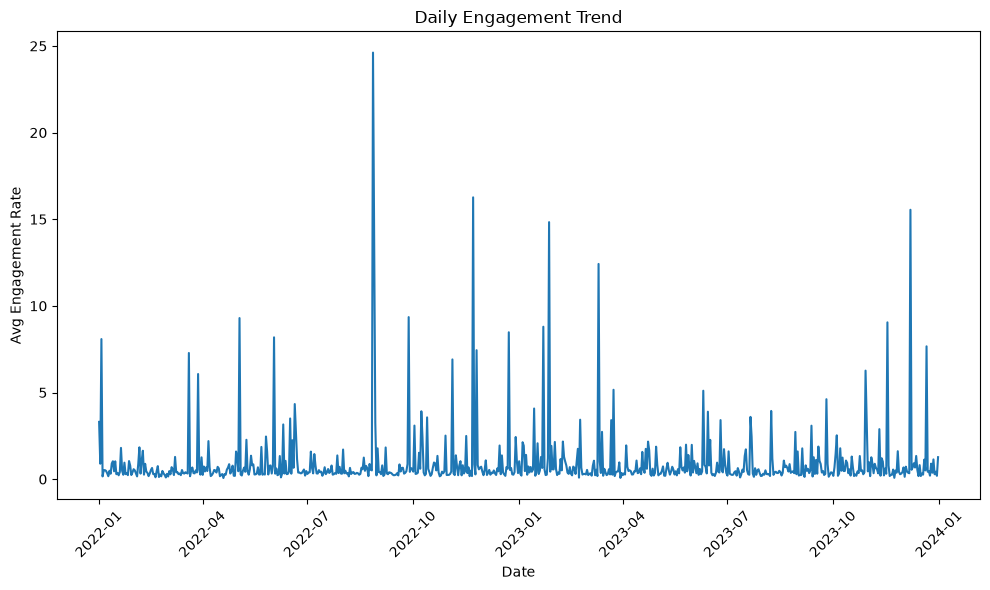

In [42]:
# Line: daily engagement trend
daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_rate'].mean()
plt.figure(figsize=(10, 6))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.xlabel('Date')
plt.ylabel('Avg Engagement Rate')
plt.title('Daily Engagement Trend')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

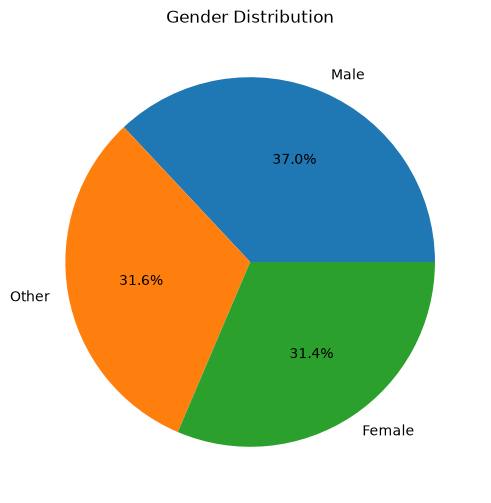

In [43]:
# Pie: gender distribution
plt.figure(figsize=(6, 6))
df['gender'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.ylabel('')
plt.title('Gender Distribution')
plt.show()
     

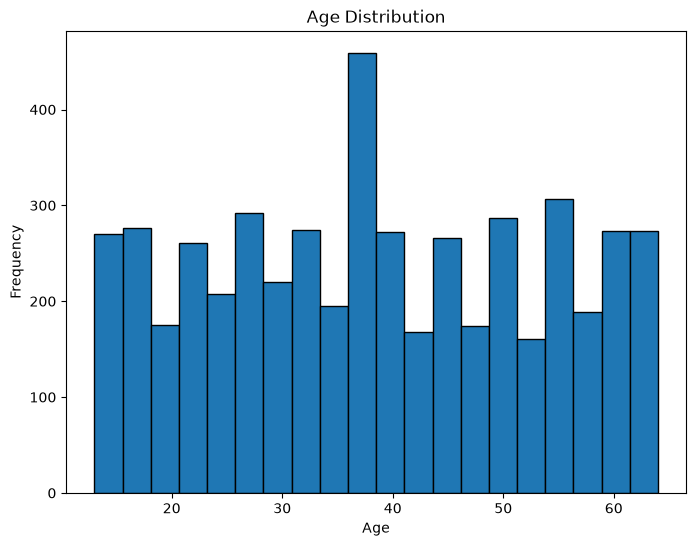

In [44]:
# Histogram: age
plt.figure(figsize=(8, 6))
plt.hist(df['age'].dropna(), bins=20, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

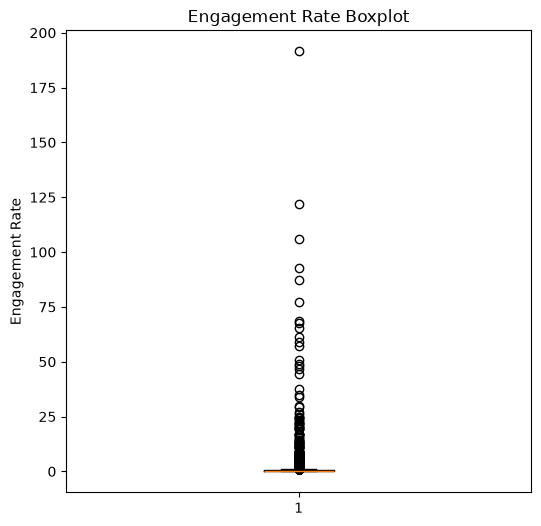

In [45]:
# Box: engagement rate
plt.figure(figsize=(6, 6))
plt.boxplot(df['engagement_rate'])
plt.ylabel('Engagement Rate')
plt.title('Engagement Rate Boxplot')
plt.show()

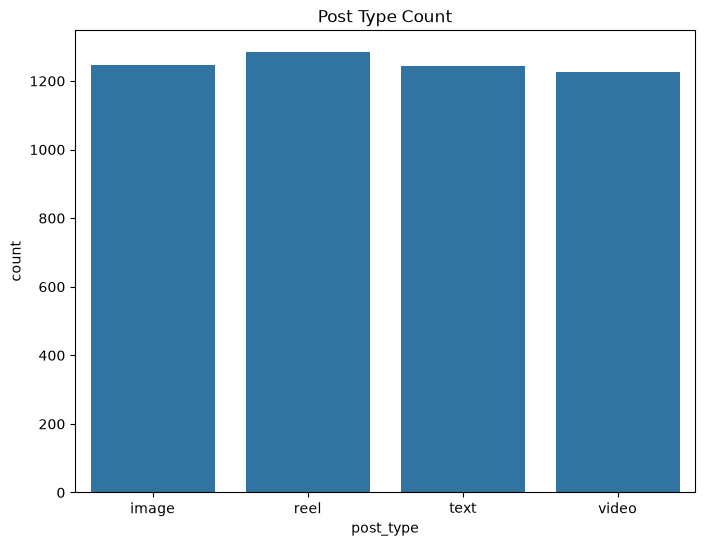

In [46]:
# Count plot: post type
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='post_type')
plt.title('Post Type Count')
plt.show()

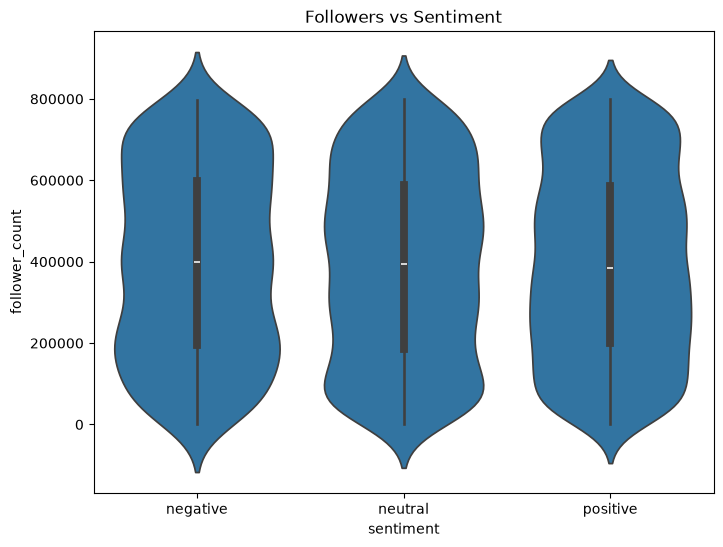

In [47]:
# Violin: followers vs sentiment
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x='sentiment', y='follower_count')
plt.title('Followers vs Sentiment')
plt.show()

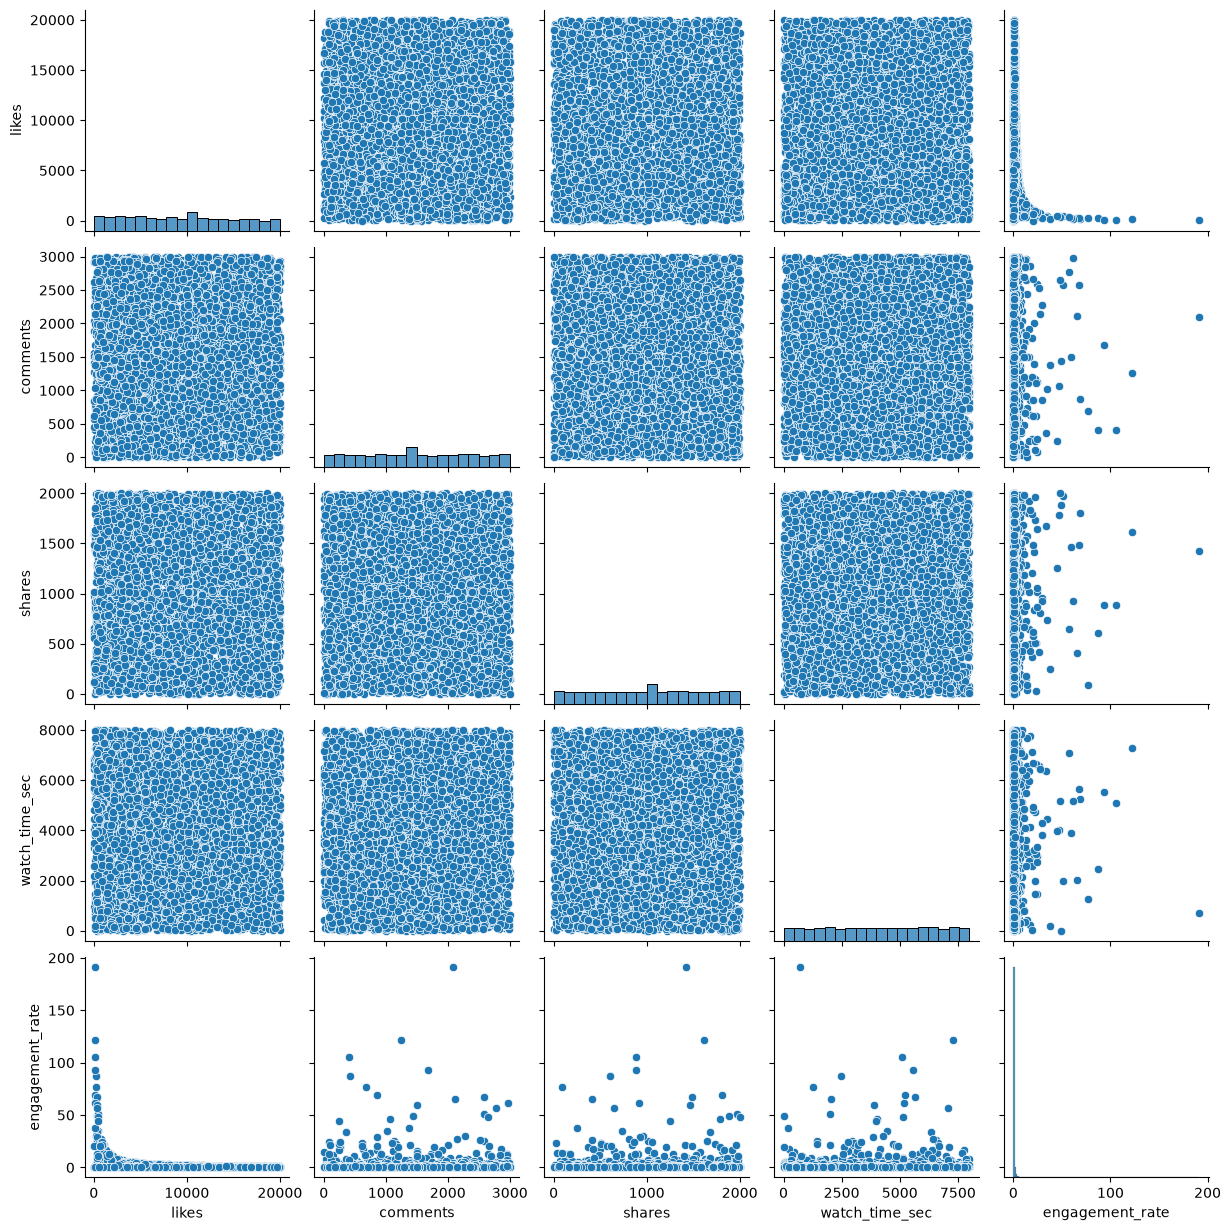

In [48]:
# Pair plot: numeric features
numeric_cols = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate']
sns.pairplot(df[numeric_cols])
plt.show()

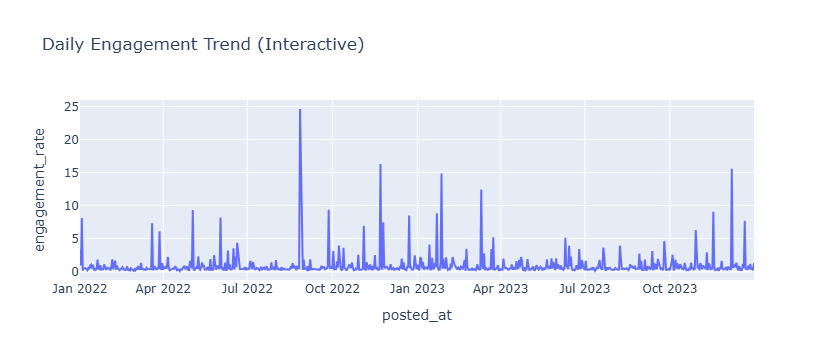

In [49]:
daily_df = daily_engagement.reset_index()
daily_df.columns = ['posted_at', 'engagement_rate']
fig = px.line(daily_df, x='posted_at', y='engagement_rate', title='Daily Engagement Trend (Interactive)')
fig.show()

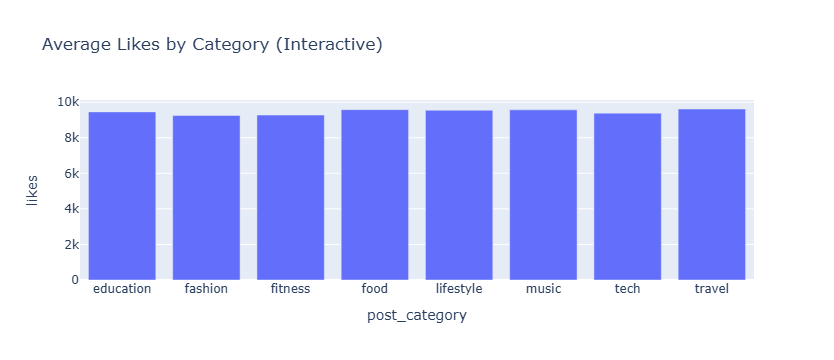

In [50]:
 #Interactive bar chart: avg likes by category
avg_likes_cat = df.groupby('post_category')['likes'].mean().reset_index()
fig = px.bar(avg_likes_cat, x='post_category', y='likes', title='Average Likes by Category (Interactive)')
fig.show()

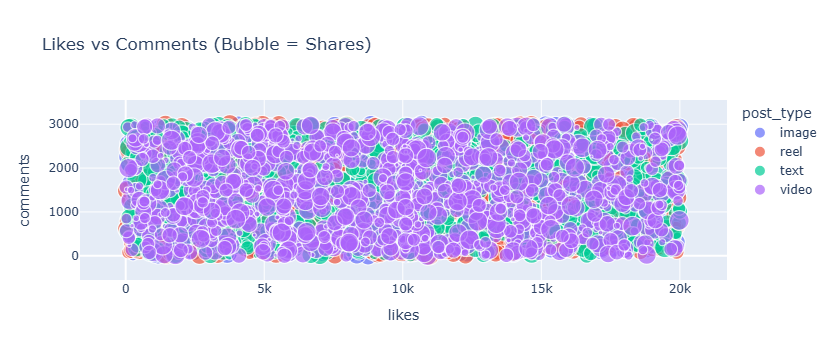

In [51]:
# Interactive bubble chart: likes vs comments, sized by shares, colored by post_type
fig = px.scatter(df, x='likes', y='comments', size='shares', color='post_type',
                  hover_data=['country'], title='Likes vs Comments (Bubble = Shares)')
fig.show()

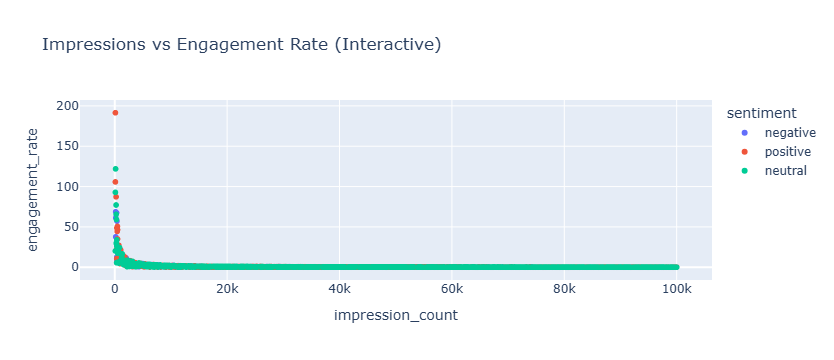

In [52]:
# Interactive scatter chart: impressions vs engagement rate
fig = px.scatter(df, x='impression_count', y='engagement_rate', color='sentiment',
                  title='Impressions vs Engagement Rate (Interactive)')
fig.show()

In [53]:
engagement_by_type = df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)
print(engagement_by_type)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64


In [54]:
engagement_by_category = df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)
print(engagement_by_category)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64


In [55]:
engagement_by_country = df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)
print(engagement_by_country)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


In [56]:
age_engagement_corr = df['age'].astype(float).corr(df['engagement_rate'])
print(f"Age vs Engagement correlation: {age_engagement_corr:.3f}")

Age vs Engagement correlation: 0.008


In [57]:
performance_by_verification = df.groupby('is_verified')['engagement_score'].mean()
print(performance_by_verification)

is_verified
False     15517.01594
True     15035.799172
Name: engagement_score, dtype: Float64


[0]


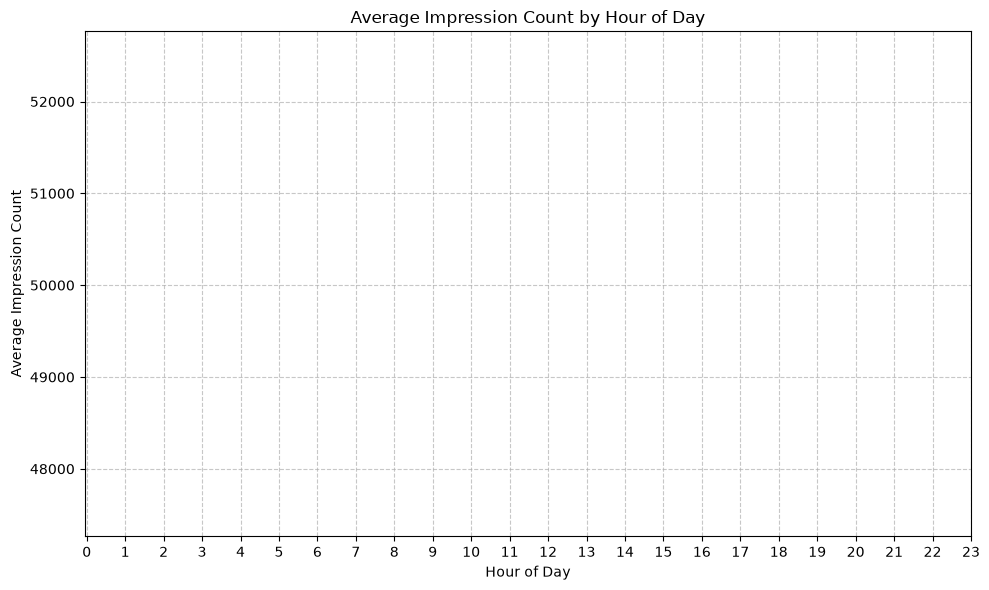

In [58]:
df['post_hour'] = df['posted_at'].dt.hour
print(df['post_hour'].unique())

hourly_impressions = df.groupby('post_hour')['impression_count'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(x='post_hour', y='impression_count', data=hourly_impressions)
plt.title('Average Impression Count by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Impression Count')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

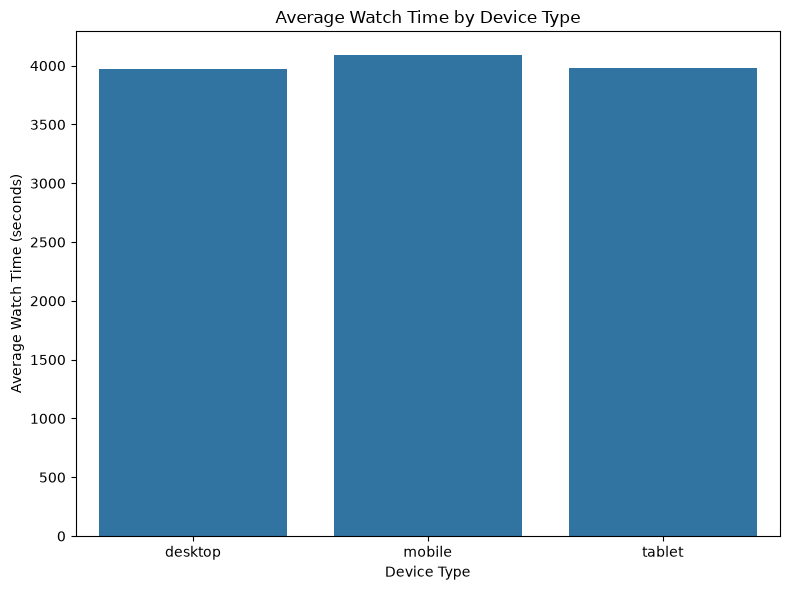

Average Watch Time by Device Type:
  device_type  watch_time_sec
0     desktop     3974.792521
1      mobile     4087.830760
2      tablet     3979.736429


In [59]:
device_watch_time = df.groupby('device_type')['watch_time_sec'].mean().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(x='device_type', y='watch_time_sec', data=device_watch_time)
plt.title('Average Watch Time by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Average Watch Time (seconds)')
plt.tight_layout()
plt.show()

print("Average Watch Time by Device Type:")
print(device_watch_time)

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64


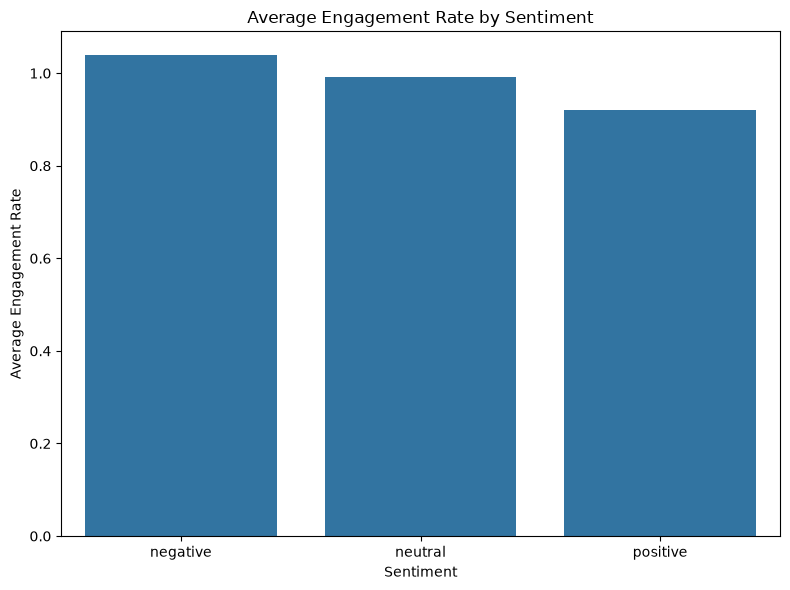

In [62]:
sentiment_engagement = df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)
print(sentiment_engagement)

plt.figure(figsize=(8, 6))
sns.barplot(x=sentiment_engagement.index, y=sentiment_engagement.values)
plt.title('Average Engagement Rate by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Engagement Rate')
plt.tight_layout()
plt.show()


In [63]:
metrics = ['likes','comments','shares','watch_time_sec','impression_count','follower_count','engagement_rate']
print(df.groupby('sentiment')[metrics].mean().round(2))

print(df[df['sentiment'].isin(['negative','neutral'])].groupby('sentiment')['post_type'].value_counts(normalize=True))
print(df[df['sentiment'].isin(['negative','neutral'])].groupby('sentiment')['is_verified'].mean())

             likes  comments   shares  watch_time_sec  impression_count  \
sentiment                                                                 
negative   9378.51   1516.09  1007.31         4054.64          50191.96   
neutral    9288.88    1528.4   996.57         4031.82          49515.97   
positive   9590.57   1480.65  1005.09         3988.65          50248.11   

           follower_count  engagement_rate  
sentiment                                   
negative        397430.43             1.04  
neutral         390568.45             0.99  
positive        394174.25             0.92  
sentiment  post_type
negative   reel         0.265625
           video        0.260417
           text         0.243750
           image        0.230208
neutral    text         0.259987
           reel         0.254093
           image        0.253438
           video        0.232482
Name: proportion, dtype: float64
sentiment
negative    0.097917
neutral     0.092993
Name: is_verified, dtype: flo